# ДЗ. Параметры простой CNN

Старинская Светлана, 3ФИИТ

## Задание

Получить разные сочетания параметров CNN и сравнить размеры карт признаков, число весов и качество.

## 1. Импорт библиотек и константы

Используем PyTorch, как в предыдущей домашней работе; блоки соответствуют Conv2D, MaxPooling и Dense из практики.

In [1]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, transforms
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DATA = Path('../.lab-data')
DATA.mkdir(exist_ok=True)
DEVICE = torch.device('cpu')
print('Устройство:', DEVICE, '| PyTorch:', torch.__version__)

Устройство: cpu | PyTorch: 2.8.0


## 2. Данные CIFAR-10

Для экспериментов на CPU берём 10 000 обучающих и 2 000 валидационных изображений. Тестовая часть CIFAR-10 не участвует в подборе.

In [2]:
# Архив CIFAR-10: https://www.cs.toronto.edu/~kriz/cifar.html
transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize((.5,)*3,(.5,)*3)])
raw = datasets.CIFAR10(DATA, train=True, download=not (DATA/'cifar-10-batches-py').exists(), transform=transform)
# Стратифицированная подвыборка: 1000 train + 200 val на класс.
rng = np.random.default_rng(SEED)
tr, va = [], []
labels = np.array(raw.targets)
for cls in range(10):
    ids = rng.permutation(np.flatnonzero(labels == cls))
    tr.extend(ids[:1000]); va.extend(ids[1000:1200])
train_data, val_data = Subset(raw,tr), Subset(raw,va)
print('Train:',len(tr),'| validation:',len(va),'| классы:',raw.classes)

Train: 10000 | validation: 2000 | классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. Архитектуры

Меняем число каналов, размер ядра, stride и размер скрытого слоя. Сначала проверяем геометрию настоящим проходом тензора.

In [3]:
def build_cnn(channels=(32,64,128),kernel=3,padding=1,stride=1,hidden=256):
    layers=[]; cin=3
    for cout in channels:
        layers.extend([nn.Conv2d(cin,cout,kernel,stride=stride,padding=padding),nn.ReLU(),nn.MaxPool2d(2)])
        cin=cout
    features=nn.Sequential(*layers)
    with torch.no_grad():n=features(torch.zeros(1,3,32,32)).numel()
    return nn.Sequential(features,nn.Flatten(),nn.Linear(n,hidden),nn.ReLU(),nn.Dropout(.5),nn.Linear(hidden,10))
configs={
 'Базовый':dict(),
 'Компактный':dict(channels=(16,32,64),hidden=128),
 'Ядро 5×5':dict(kernel=5,padding=2),
 'Stride 2':dict(channels=(32,64),stride=2,hidden=128),
}
for name,cfg in configs.items():
    m=build_cnn(**cfg);x=torch.zeros(1,3,32,32)
    print('\n',name,'| параметров:',sum(p.numel() for p in m.parameters()))
    for layer in m[0]:
        x=layer(x)
        if isinstance(layer,(nn.Conv2d,nn.MaxPool2d)):print(type(layer).__name__,tuple(x.shape))


 Базовый | параметров: 620362
Conv2d (1, 32, 32, 32)
MaxPool2d (1, 32, 16, 16)
Conv2d (1, 64, 16, 16)
MaxPool2d (1, 64, 8, 8)
Conv2d (1, 128, 8, 8)
MaxPool2d (1, 128, 4, 4)

 Компактный | параметров: 156074
Conv2d (1, 16, 32, 32)
MaxPool2d (1, 16, 16, 16)
Conv2d (1, 32, 16, 16)
MaxPool2d (1, 32, 8, 8)
Conv2d (1, 64, 8, 8)
MaxPool2d (1, 64, 4, 4)

 Ядро 5×5 | параметров: 785738
Conv2d (1, 32, 32, 32)
MaxPool2d (1, 32, 16, 16)
Conv2d (1, 64, 16, 16)
MaxPool2d (1, 64, 8, 8)
Conv2d (1, 128, 8, 8)
MaxPool2d (1, 128, 4, 4)

 Stride 2 | параметров: 53578
Conv2d (1, 32, 16, 16)
MaxPool2d (1, 32, 8, 8)
Conv2d (1, 64, 4, 4)
MaxPool2d (1, 64, 2, 2)


## 4. Обучение и сравнение

Одинаковые данные, seed, Adam и три эпохи. На выходе модели — logits; Softmax применяется только для вероятностей.


Базовый
Эпоха 1: loss=1.9658, train=26.92%, val=40.60%, время=7.4 с
Эпоха 2: loss=1.6147, train=40.14%, val=48.30%, время=14.6 с
Эпоха 3: loss=1.4578, train=46.93%, val=50.55%, время=21.9 с

Компактный
Эпоха 1: loss=2.0467, train=23.96%, val=36.40%, время=4.4 с
Эпоха 2: loss=1.7549, train=35.60%, val=43.65%, время=8.7 с
Эпоха 3: loss=1.6086, train=41.79%, val=45.75%, время=13.1 с

Ядро 5×5
Эпоха 1: loss=1.9822, train=26.46%, val=40.40%, время=15.2 с
Эпоха 2: loss=1.6528, train=38.70%, val=47.05%, время=35.2 с
Эпоха 3: loss=1.4775, train=46.05%, val=50.20%, время=55.3 с

Stride 2
Эпоха 1: loss=2.1113, train=21.64%, val=29.70%, время=4.1 с
Эпоха 2: loss=1.8582, train=31.39%, val=34.85%, время=8.1 с
Эпоха 3: loss=1.7279, train=36.23%, val=37.45%, время=12.5 с
Базовый val=50.55%, время=21.9 с
Компактный val=45.75%, время=13.1 с
Ядро 5×5 val=50.20%, время=55.3 с
Stride 2 val=37.45%, время=12.5 с
Лучшее качество в этом запуске: Базовый


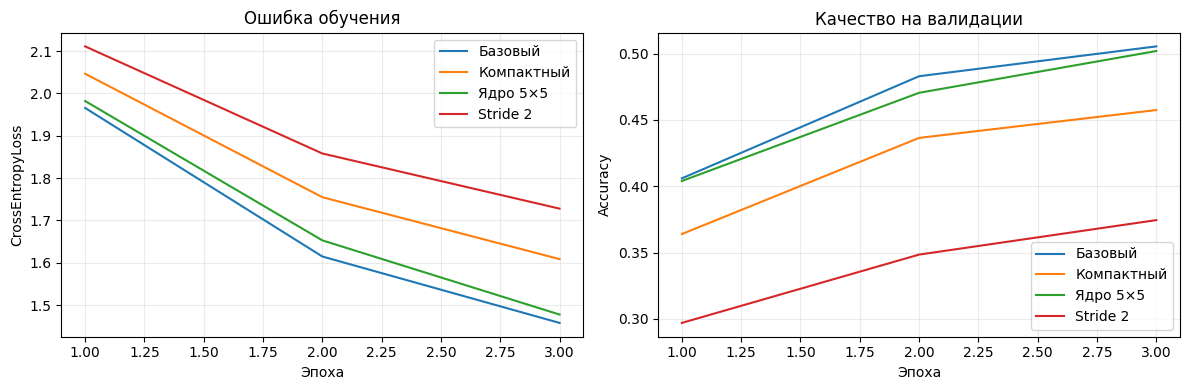

In [4]:
def fit(model, train_data, val_data, epochs=3, lr=0.001):
    torch.manual_seed(SEED)
    loader = DataLoader(train_data, batch_size=128, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    val_loader = DataLoader(val_data, batch_size=256)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = []
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        loss_sum = correct = total = 0
        for x, y in loader:
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            total += len(y)
        model.eval()
        vc = vn = 0
        with torch.inference_mode():
            for x, y in val_loader:
                vc += (model(x).argmax(1) == y).sum().item()
                vn += len(y)
        row = (loss_sum / total, correct / total, vc / vn, time.perf_counter()-start)
        history.append(row)
        print(f'Эпоха {epoch+1}: loss={row[0]:.4f}, train={row[1]:.2%}, val={row[2]:.2%}, время={row[3]:.1f} с')
    return np.array(history)

def plot_histories(histories):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in histories.items():
        axes[0].plot(np.arange(1,len(h)+1),h[:,0],label=name)
        axes[1].plot(np.arange(1,len(h)+1),h[:,2],label=name)
    axes[0].set(title='Ошибка обучения',xlabel='Эпоха',ylabel='CrossEntropyLoss')
    axes[1].set(title='Качество на валидации',xlabel='Эпоха',ylabel='Accuracy')
    for ax in axes:ax.legend();ax.grid(alpha=.25)
    plt.tight_layout();plt.show()

histories={}
for name,cfg in configs.items():
    torch.manual_seed(SEED);print('\n'+name)
    histories[name]=fit(build_cnn(**cfg),train_data,val_data)
plot_histories(histories)
for name,h in histories.items():print(name,f'val={h[-1,2]:.2%}, время={h[-1,3]:.1f} с')
best=max(histories,key=lambda n:histories[n][-1,2])
print('Лучшее качество в этом запуске:',best)

## Вывод

За три эпохи базовая сеть получила **50,55% accuracy** на validation. Компактная сеть — **45,75%** при 156 074 параметрах вместо 620 362. Ядро 5×5 дало **50,20%**, но увеличило время с 21,9 до 55,3 с. Вариант со stride=2 оказался самым быстрым (12,5 с), однако получил только **37,45%**. В этом эксперименте ускорение за счёт сильного уменьшения карт признаков привело к потере качества. Результаты относятся к началу обучения на фиксированной подвыборке, а не к предельной точности архитектур.